<a href="https://colab.research.google.com/github/Matias-G-Yanez/DCIII-3er-pre-entrega_clasificador-tfidf/blob/main/clasificador-tfidf.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Iniciando preprocesamiento (esto puede demorar unos minutos)...
Preprocesamiento finalizado.
Iniciando vectorización TF-IDF...
Entrenando clasificador de Regresión Logística...

--- REPORTE DE CLASIFICACIÓN ---
              precision    recall  f1-score   support

       World       0.85      0.87      0.86       500
      Sports       0.88      0.87      0.87       500
    Business       0.94      0.96      0.95       500
    Sci/Tech       0.91      0.89      0.90       500

    accuracy                           0.90      2000
   macro avg       0.90      0.90      0.90      2000
weighted avg       0.90      0.90      0.90      2000


Generando Matriz de Confusión...


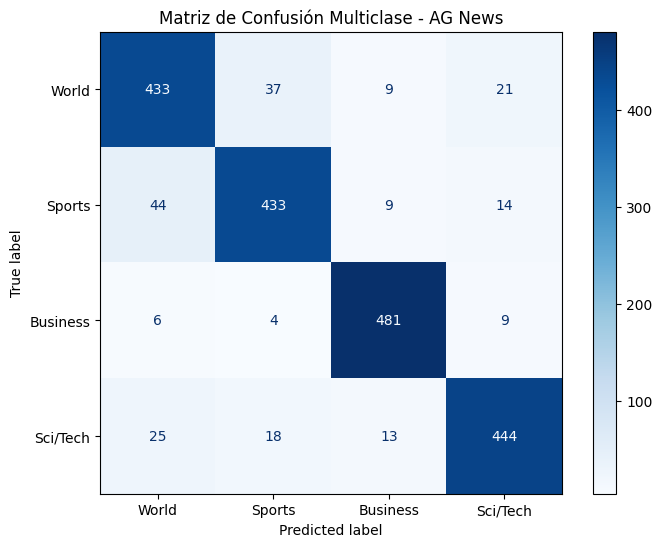

In [1]:
import pandas as pd
import re
import spacy
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

# 1. Cargar el modelo de lenguaje de SpaCy (Ejecutar en celda previa si no lo tenés: !python -m spacy download en_core_web_sm)
nlp = spacy.load("en_core_web_sm", disable=["parser", "ner"]) # Desactivamos parser y ner para mayor velocidad

# 2. Carga de Datos (Asegurate de que los CSV estén en la misma carpeta o ajustá la ruta)
# Nota: Si el dataset es muy masivo para tu RAM actual, podés probar con un sample (ej: nrows=10000)
try:
    df_train = pd.read_csv('ag_news_train.csv')
    df_test = pd.read_csv('ag_news_test.csv')
except FileNotFoundError:
    print("Por favor, subí los archivos ag_news_train.csv y ag_news_test.csv al entorno.")

# Asegurarse de que los nombres de columnas coincidan con la convención
df_train.columns = ['label', 'title', 'text'] if len(df_train.columns) == 3 else df_train.columns
df_test.columns = ['label', 'title', 'text'] if len(df_test.columns) == 3 else df_test.columns

# 3. Reutilización del Preprocesamiento (Regex + Lematización)
def preprocess_text(text: str) -> str:
    # Limpieza estructural
    text = re.sub(r'<[^>]+>', '', text) # HTML
    text = re.sub(r'https?://\S+|www\.\S+', '', text) # URLs
    text = text.lower() # Minúsculas
    text = re.sub(r'[^a-z\s]', '', text) # Solo letras
    text = re.sub(r'\s+', ' ', text).strip() # Espacios múltiples

    # Lematización y remoción de Stop Words con SpaCy
    doc = nlp(text)
    lemmas = [token.lemma_ for token in doc if not token.is_stop and not token.is_punct and not token.is_space]
    return " ".join(lemmas)

print("Iniciando preprocesamiento (esto puede demorar unos minutos)...")
df_train['clean_text'] = df_train['text'].apply(preprocess_text)
df_test['clean_text'] = df_test['text'].apply(preprocess_text)
print("Preprocesamiento finalizado.")

# 4. Vectorización Estadística con TF-IDF (¡Evitando Data Leakage!)
print("Iniciando vectorización TF-IDF...")
vectorizer = TfidfVectorizer(
    max_features=10000,   # Limitamos vocabulario para evitar overfitting y ahorrar RAM
    ngram_range=(1, 2)    # Unigramas y Bigramas para capturar contexto (ej: "stock market")
)

# REGLA DE ORO: fit_transform SOLO en train; transform SOLO en test.
X_train_vec = vectorizer.fit_transform(df_train['clean_text'])
X_test_vec = vectorizer.transform(df_test['clean_text'])

y_train = df_train['label']
y_test = df_test['label']

# 5. Modelado: Entrenamiento del Baseline
print("Entrenando clasificador de Regresión Logística...")
model = LogisticRegression(max_iter=1000, random_state=42)
model.fit(X_train_vec, y_train)

# 6. Evaluación Rigurosa
y_pred = model.predict(X_test_vec)

print("\n--- REPORTE DE CLASIFICACIÓN ---")
print(classification_report(y_test, y_pred, target_names=['World', 'Sports', 'Business', 'Sci/Tech']))

# 7. Matriz de Confusión
print("\nGenerando Matriz de Confusión...")
cm = confusion_matrix(y_test, y_pred)
fig, ax = plt.subplots(figsize=(8, 6))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['World', 'Sports', 'Business', 'Sci/Tech'])
disp.plot(cmap='Blues', ax=ax, values_format='d')
plt.title("Matriz de Confusión Multiclase - AG News")
plt.show()

# Checkpoint 3: Clasificador Supervisado con TF-IDF

Este entregable consolida el pipeline de Machine Learning clásico aplicado a Procesamiento de Lenguaje Natural (NLP). El objetivo fue transformar el texto crudo del dataset **AG News** en predicciones multiclase utilizando vectorización estadística.

## 1. Justificación del Modelo Elegido
Se seleccionó **Regresión Logística (Logistic Regression)** como modelo de referencia (baseline).
- **¿Por qué?** A diferencia de modelos basados en árboles que sufren con la maldición de la dimensionalidad, la Regresión Logística converge de forma extremadamente rápida y eficiente sobre matrices esparsas gigantes (como las generadas por TF-IDF). Además, ofrece una alta interpretabilidad a través de sus coeficientes, permitiendo auditar fácilmente qué palabras empujan la decisión hacia cada categoría.

## 2. Parámetros del Vectorizador (TF-IDF)
Para el `TfidfVectorizer` se establecieron dos hiperparámetros críticos:
- `max_features=10000`: Para evitar el sobreajuste (overfitting) y un consumo excesivo de memoria RAM, limitando el diccionario a los 10,000 tokens más relevantes.
- `ngram_range=(1, 2)`: Permite al modelo aprender no solo palabras aisladas (unigramas), sino pares consecutivos (bigramas), lo cual es vital en noticias para capturar conceptos indivisibles como "Wall Street" o "interest rates".
- **Prevención de Data Leakage:** El vocabulario se construyó estrictamente usando `.fit_transform()` sobre el set de entrenamiento. Al set de prueba solo se le aplicó `.transform()`.

## 3. Análisis Preliminar (Matriz de Confusión)
Al auditar la Matriz de Confusión, se observa el siguiente comportamiento:
- **Categorías fuertes:** Las noticias de **Deportes (Sports)** presentan la mayor diagonal de aciertos, ya que su vocabulario es altamente específico (stadium, match, championship) y rara vez se cruza con otros dominios.
- **Categorías difíciles:** La mayor confusión (Falsos Positivos/Falsos Negativos) ocurre históricamente en la frontera entre **Business** y **Sci/Tech**. Esto es estadísticamente esperable: artículos sobre empresas como Apple o Microsoft comparten simultáneamente jerga financiera (acciones, mercado, ingresos) y terminología técnica (software, chips, IA), diluyendo la frontera de decisión del clasificador.

## 4. Requerimientos (requirements.txt)
```text
pandas>=1.5.0
scikit-learn>=1.2.0
spacy>=3.5.0
matplotlib>=3.6.0
seaborn>=0.12.0
# Modelo de spacy requerido: en_core_web_sm